# Predicción de la gravedad de siniestros viales en la Ciudad de Buenos Aires
## Notebook 3 — Aprendizaje no supervisado: ¿qué tipos de siniestros hay?

**4ª pre-entrega.** Modelo de clustering desde el AED hasta su mejora: se elige un algoritmo (**K-Means**), se ajusta un modelo base, se revisa qué falla y se mejora con decisiones explícitas y un criterio fijado de antemano.

**Objetivo.** Agrupar los siniestros de CABA según sus **circunstancias** (cuándo ocurrieron, en qué tipo de vía, quiénes fueron las víctimas y contra qué chocaron) para encontrar perfiles típicos. La **gravedad no se usa para agrupar**: se usa al final para ver si algún grupo concentra más siniestros graves o mortales (validación externa). Eso conecta este notebook con el modelo supervisado del Notebook 2.

**Datos.** `hechos_limpio.csv` y `victimas_limpio.csv`, generados por el Notebook 2.

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 60)

## Cargar y leer el dataset

In [94]:
# En Colab hay que montar Drive; si no estamos en Colab, este paso se saltea.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/datos/"
except ImportError:
    RUTA = ""          # ejecución local: los CSV están en la misma carpeta del notebook

hechos = pd.read_csv(RUTA + "hechos_limpio.csv", sep=";", low_memory=False)
victimas = pd.read_csv(RUTA + "victimas_limpio.csv", sep=";", low_memory=False)

print("hechos  :", hechos.shape)
print("victimas:", victimas.shape)

hechos  : (65818, 28)
victimas: (75193, 11)


---
# Parte 1 — AED: continuación de los Notebooks 1 y 2

El AED de este proyecto ya está hecho en dos etapas y **no se repite**. Este notebook parte de sus conclusiones y sólo agrega lo que necesita un modelo de clustering.

| Notebook | Qué resolvió | Cómo se usa acá |
|---|---|---|
| **1 — EDA y limpieza** (calidad) | Faltantes disfrazados (`"SD"`, `"#¡REF!"`) → `SIN DATOS`; categorías normalizadas (tipografía y equivalencias); edad asimétrica → mediana; edades imposibles → faltante; siniestros con muchas víctimas son **reales** y no se eliminan; duplicados de `victimas` son personas distintas | Se trabaja sobre `hechos_limpio.csv` y `victimas_limpio.csv`, que ya traen todo eso aplicado |
| **2 — Modelo de clasificación** (EDA orientado a la gravedad) | Gravedad derivada de los conteos; desbalance 94 / 4,5 / 1 %; la gravedad sube **de madrugada** (×3), **los fines de semana** y en autopista; el **peatón** y la **moto** son las víctimas más expuestas; `SIN DATOS` es casi siempre leve (sesgo de registro); entre comunas, diferencias moderadas | Orienta qué variables entran al clustering y cómo representarlas; la gravedad queda afuera del agrupamiento y se usa para validar |

Lo que cambia es la pregunta. El Notebook 2 preguntaba **qué variables se asocian con la gravedad**. Acá la pregunta es **cómo se ven esas variables en términos de distancia**, porque K-Means agrupa por distancia: importan la escala de cada variable, su forma y las categorías raras.

## 1.1 Feature engineering: misma tabla que el Notebook 2

Se repite exactamente la construcción del Notebook 2 (sección 3.2): una fila por siniestro, con la cantidad de víctimas y su edad media calculada sólo con edades observadas.

In [95]:
edad_observada = victimas["edad_victima"].where(~victimas["edad_imputada"])

resumen_victimas = (victimas.assign(edad_observada=edad_observada)
                    .groupby("id_siniestro")
                    .agg(cantidad_victimas=("id_siniestro", "size"),
                         edad_media_victimas=("edad_observada", "mean")))

datos = hechos.merge(resumen_victimas, on="id_siniestro", how="left")
print(datos.shape)

(65818, 30)


## 1.2 Selección de variables: de las predictoras del Notebook 2 a las del clustering

El punto de partida son las 10 predictoras del Notebook 2 (sección 3.3). Para agrupar por **circunstancias** se ajustan así:

| Variable del Notebook 2 | En el clustering | Por qué |
|---|---|---|
| `hora` | **entra** | la gravedad cambia mucho por hora (Notebook 2, 2.3) |
| `dia_semana` | **entra** (en la mejora pasa a fin de semana) | la diferencia relevante es fin de semana vs. día hábil (Notebook 2, 2.3) |
| `cantidad_victimas`, `edad_media_victimas` | **entran** | describen quiénes participan |
| `tipo_de_via_siniestro`, `modo_desplazamiento_victima`, `contraparte_siniestro` | **entran** | describen dónde y quién choca contra quién (Notebook 2, 2.2 y 2.3) |
| `mes`, `anio` | **salen** | ubican el siniestro en el calendario, no describen cómo ocurrió; agruparían por período |
| `comuna` | **sale** | sumaría 16 indicadoras con diferencias sólo moderadas (Notebook 2, 2.3); la ubicación se usa después, en el mapa, para interpretar |
| `gravedad` | **sale** | es lo que se quiere validar; usarla para agrupar sería circular |

In [96]:
numericas = ["hora", "dia_semana", "cantidad_victimas", "edad_media_victimas"]
categoricas = ["tipo_de_via_siniestro", "modo_desplazamiento_victima", "contraparte_siniestro"]

print("Faltantes (%):")
print((datos[numericas + categoricas].isna().mean() * 100).round(2))

Faltantes (%):
hora                            0.12
dia_semana                      0.00
cantidad_victimas               0.00
edad_media_victimas            31.24
tipo_de_via_siniestro           0.00
modo_desplazamiento_victima     0.00
contraparte_siniestro           0.00
dtype: float64


## 1.3 EDA para clustering: escala y distribución de las numéricas

           hora  dia_semana  cantidad_victimas  edad_media_victimas
count  65737.00    65818.00           65818.00             45258.00
mean      13.64        2.76               1.14                38.14
std        5.54        1.87               0.54                15.44
min        0.00        0.00               1.00                 0.00
25%       10.00        1.00               1.00                27.00
50%       14.00        3.00               1.00                35.00
75%       18.00        4.00               1.00                47.00
max       23.00        6.00              26.00               100.00


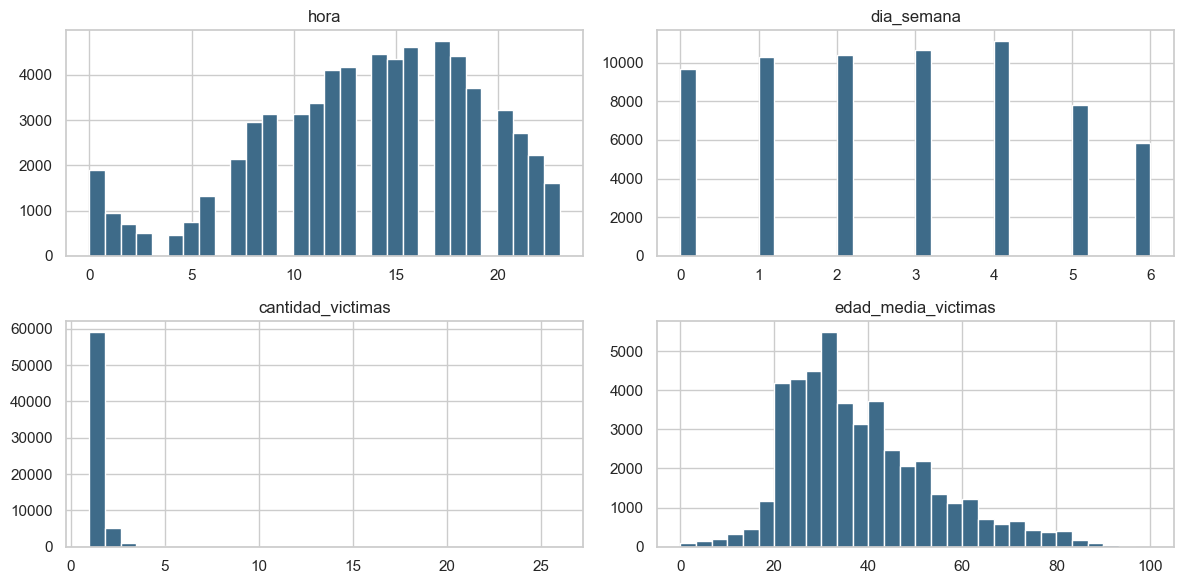

In [97]:
print(datos[numericas].describe().round(2))

datos[numericas].hist(bins=30, figsize=(12, 6), color="#3E6B89")
plt.tight_layout()
plt.show()

**Lectura.** Las escalas son muy distintas: la edad va de 0 a 100, la hora de 0 a 23, el día de 0 a 6 y la cantidad de víctimas casi siempre es 1. Sin estandarizar, la edad dominaría la distancia. Además:

- **`hora` es circular**: las 23 h y las 0 h están a 1 hora, pero numéricamente a 23 unidades. Como el Notebook 2 mostró que la gravedad se concentra de madrugada (alrededor de las 0 a 5 h), lo que importa no es el número de la hora sino si el siniestro es **nocturno**. El gráfico siguiente define qué horas cuentan como nocturnas.
- **`dia_semana`** también es circular, pero lo que importa (Notebook 2) es si es **fin de semana**.
- **`cantidad_victimas`** es muy asimétrica: casi todos los siniestros tienen 1 víctima y unos pocos llegan a 26. El Notebook 1 (sección 8) decidió que son siniestros múltiples **reales**, así que no se eliminan; es esperable que formen un grupo propio.
- **`edad_media_victimas`** mantiene la asimetría positiva que el Notebook 1 (sección 7) encontró en la edad, y falta en el 31 % de los siniestros (los que no tienen ninguna edad registrada). Como en los Notebooks 1 y 2, se imputa con la mediana.

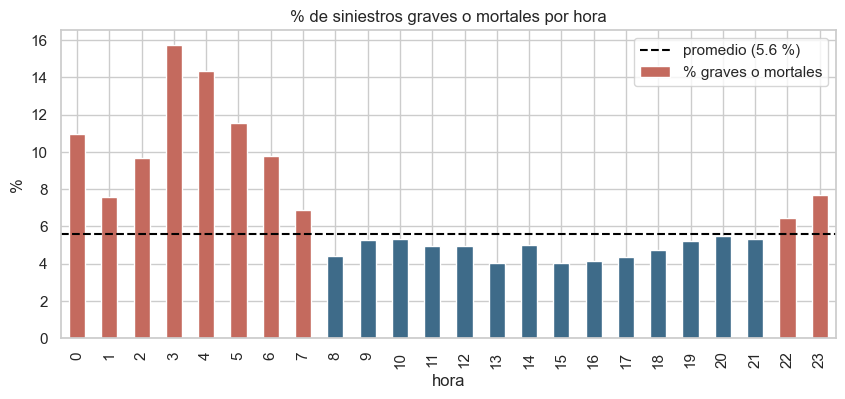

In [98]:
# % de siniestros graves o mortales por hora (como en el Notebook 2, sección 2.3)
grave_o_mortal = datos["gravedad"].isin(["GRAVE", "MORTAL"])
por_hora = grave_o_mortal.groupby(datos["hora"]).mean() * 100
por_hora.index = por_hora.index.astype(int)
promedio = grave_o_mortal.mean() * 100

# En rojo, las horas por encima del promedio
por_hora.plot(kind="bar", figsize=(10, 4), label="% graves o mortales", color=["#C46A5E" if p > promedio else "#3E6B89" for p in por_hora])
plt.axhline(promedio, color="black", linestyle="--", label=f"promedio ({promedio:.1f} %)")
plt.title("% de siniestros graves o mortales por hora")
plt.xlabel("hora")
plt.ylabel("%")
plt.legend()
plt.show()

**Lectura.** La gravedad no sube de a poco con la hora: cambia de nivel. Entre las 8 y las 21 h se mantiene entre 4 % y 5,5 %, por debajo del promedio (5,6 %). Entre las **22 y las 7 h** está siempre por encima, con un pico a las 3 h (15,7 %, casi el triple). Las horas por encima del promedio forman un **bloque continuo**, así que el criterio para definir `nocturno` sale directo del gráfico: **1 si el siniestro ocurre entre las 22 y las 7 h, 0 si no**. Esto también resuelve que la hora sea circular: las 23 h y las 0 h quedan del mismo lado.

## 1.4 EDA para clustering: peso de las categorías raras

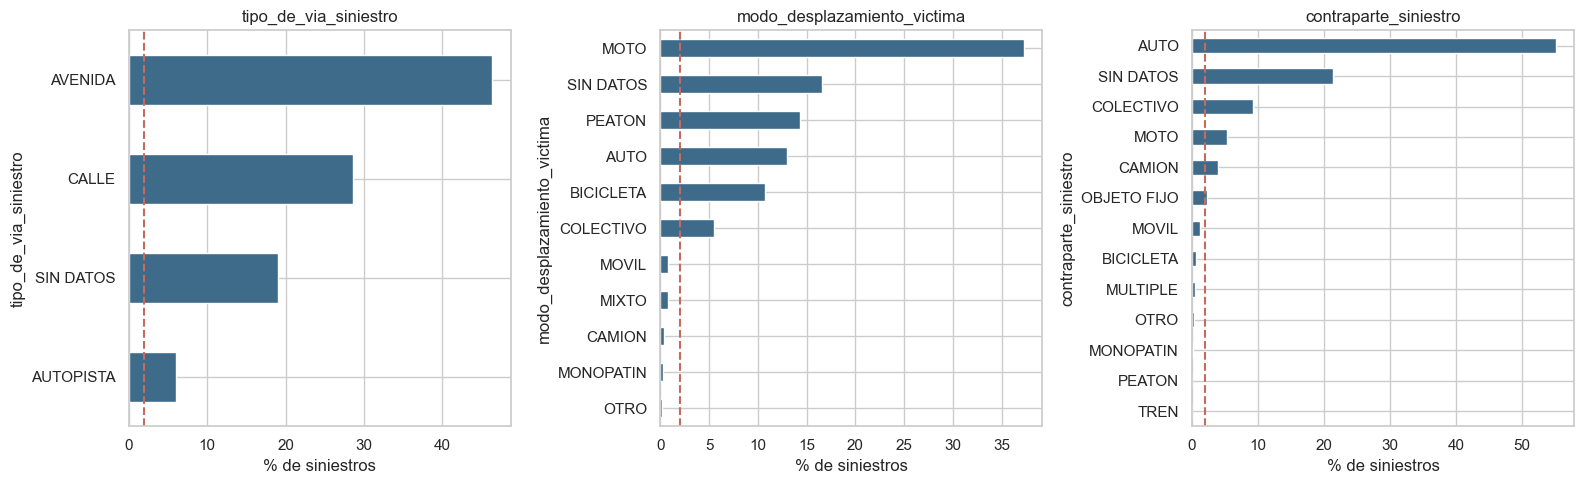

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, columna in zip(axes, categoricas):
    (datos[columna].value_counts(normalize=True) * 100).sort_values().plot(kind="barh", ax=ax, color="#3E6B89")
    ax.axvline(2, color="#C46A5E", linestyle="--")       # umbral de categoría rara
    ax.set_title(columna)
    ax.set_xlabel("% de siniestros")

plt.tight_layout()
plt.show()

**Lectura.** Varias categorías tienen menos del 2 % de los siniestros (línea roja): monopatín, camión, tren, peatón como contraparte, etc. Al pasarlas a variables indicadoras (one-hot) y **estandarizarlas**, una indicadora rara queda con valores enormes (una categoría del 0,3 % pasa de 1 a ~18 desvíos) y K-Means tiende a armar grupos sólo para ellas. `SIN DATOS` es frecuente (~20 %). Se conserva como categoría, igual que en los Notebooks 1 y 2: eliminarla quitaría casi 4 de cada 10 siniestros, y el Notebook 2 mostró que no es azar sino un sesgo de registro de los siniestros leves.

## 1.5 EDA para clustering: redundancia entre numéricas

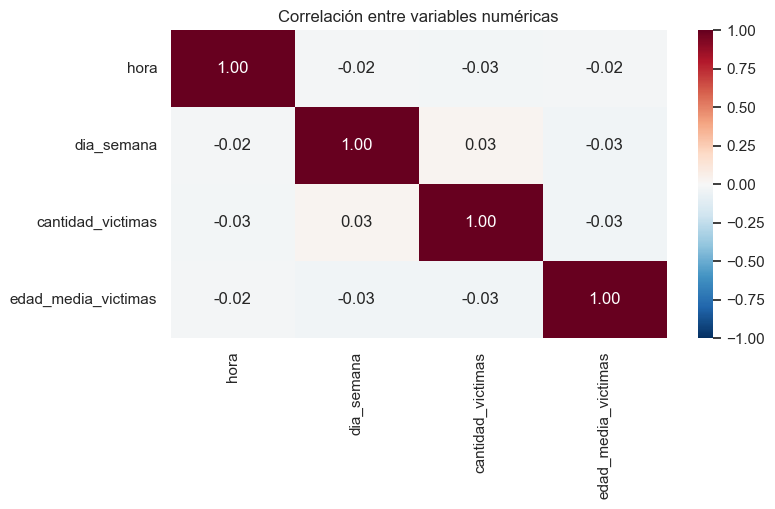

In [100]:
sns.heatmap(datos[numericas].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

**Lectura.** Las correlaciones son prácticamente nulas (todas menores a 0,05 en valor absoluto): cada variable numérica aporta información distinta, no hace falta descartar ninguna por redundante.

## 1.6 Preprocesamiento: decisiones que surgen del EDA

> **Por qué escalar es obligatorio en K-Means:** igual que en las redes neuronales (Clase 24), si las variables tienen rangos muy distintos, las de magnitud grande dominan. En una red dominan el gradiente; en K-Means dominan la **distancia**. Sin escalar, la edad (0 a 100) decidiría sola los grupos y la hora o el fin de semana casi no contarían. `StandardScaler` lleva cada columna a media 0 y desvío 1: $x' = \frac{x - \mu}{\sigma}$.
>
> A diferencia del aprendizaje supervisado, acá **no hay train/test**: no hay respuesta que predecir ni fuga de información que evitar, así que el escalador se ajusta con todos los datos.

| Problema detectado | Decisión |
|---|---|
| Faltantes: `hora` (0,1 %) y `edad_media_victimas` (31 %, siniestros sin ninguna edad registrada) | imputar con la mediana; en la edad es una simplificación que se anota como limitación |
| Escalas muy distintas | estandarizar las numéricas (`StandardScaler`) |
| Lo que importa de la hora es si es de noche | `nocturno` (se aplica en la mejora, Parte 3) |
| Categorías raras | agruparlas (se aplica en la mejora, Parte 3) |
| `gravedad` | **no entra** al clustering, sólo para interpretar |

El modelo base de la Parte 2 aplica sólo las dos primeras decisiones, que son las mínimas para que K-Means funcione. Así se puede medir cuánto aportan las otras.

In [101]:
datos["hora"] = datos["hora"].fillna(datos["hora"].median())
datos["edad_media_victimas"] = datos["edad_media_victimas"].fillna(datos["edad_media_victimas"].median())
print(datos[numericas].isna().sum())

hora                   0
dia_semana             0
cantidad_victimas      0
edad_media_victimas    0
dtype: int64


---
# Parte 2 — Machine learning no supervisado: modelo base con K-Means

**Por qué K-Means:** es el algoritmo visto en clase, escala bien a 65.000 filas y da centroides fáciles de interpretar como "siniestro típico" de cada grupo. Su limitación es que supone grupos más o menos esféricos y es sensible a la escala, por eso el preprocesamiento importa.

**Modelo base:** numéricas tal cual + one-hot de todas las categorías, **todo estandarizado**.

In [102]:
X_base = pd.get_dummies(datos[numericas + categoricas], columns=categoricas, dtype=float)
X_base = StandardScaler().fit_transform(X_base)
print("matriz base:", X_base.shape)

matriz base: (65818, 32)


## 2.1 Elección de la cantidad de grupos (k)

Se prueban k de 2 a 10 con dos criterios:

- **Método del codo (inercia):** suma de distancias al centroide. Siempre baja con más grupos; se busca el punto donde deja de bajar mucho.
- **Silueta:** de -1 a 1; cuanto más alto, más separados están los grupos. Se calcula sobre una muestra de 10.000 siniestros para que no tarde.

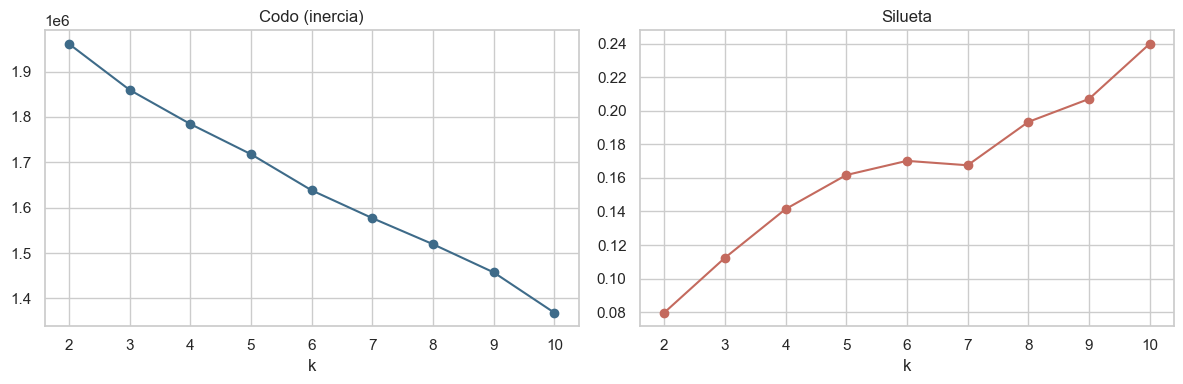

,inercia,silueta
k,,
2,1961334.440,0.080
3,1859798.111,0.112
4,1784587.848,0.141
5,1717930.287,0.162
6,1638275.532,0.170
7,1576962.865,0.168
8,1519455.277,0.193
9,1457307.595,0.207
10,1368338.783,0.240


In [103]:
resultados_base = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_base)
    resultados_base.append({"k": k,
                            "inercia": kmeans.inertia_,
                            "silueta": silhouette_score(X_base, kmeans.labels_, sample_size=10000, random_state=42)})
resultados_base = pd.DataFrame(resultados_base).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
resultados_base["inercia"].plot(marker="o", ax=axes[0], color="#3E6B89", title="Codo (inercia)")
resultados_base["silueta"].plot(marker="o", ax=axes[1], color="#C46A5E", title="Silueta")
plt.tight_layout()
plt.show()
resultados_base.round(3)

**¿Qué nos dicen estos gráficos?**

* **No hay codo.** La inercia baja de a poco y casi en línea recta, sin un punto donde la mejora se frene de golpe. El gráfico no sugiere ningún k en particular.
* **El Silhouette es muy bajo.** Va de 0,08 a 0,24, cuando 1 es lo ideal. Los grupos quedan pegados unos a otros y muchos siniestros están en el límite entre dos grupos.
* **El Silhouette sube cada vez que agregamos un grupo.** Normalmente sube hasta un k y después baja, y ese pico marca el mejor k. Acá no pasa: siempre sube un poco más.

**¿Por qué pasa esto?** Al convertir las categorías en columnas de 0 y 1 (one-hot) y escalarlas, las categorías raras quedaron con valores enormes. Por ejemplo, la columna de las víctimas que iban en un vehículo oficial (`MOVIL`, menos del 1 % de los siniestros) pasa de valer 1 a valer 11 después de escalar. Esos siniestros quedan tan lejos del resto que K-Means les arma un grupo propio. Cada grupo nuevo que agregamos se queda con otra categoría rara, y por eso el Silhouette sube.

**Conclusión:** los grupos no se arman por las circunstancias del siniestro (hora, día, edad, tipo de víctima). Se arman por cuál categoría rara tiene cada uno. El problema no es K-Means sino cómo le presentamos los datos, y eso es lo que corregimos en la mejora más adelante.

Para poder comparar con la mejora se fija **k = 6** y se mira qué grupos arma.

In [104]:
datos["cluster_base"] = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(X_base)

print("Tamaño de cada grupo:")
print(datos["cluster_base"].value_counts().sort_index())

# Categoría más frecuente de cada variable dentro de cada grupo
datos.groupby("cluster_base")[categoricas].agg(lambda s: s.value_counts(normalize=True).round(2).head(1).to_dict())

Tamaño de cada grupo:
cluster_base
0     9348
1    24554
2    10923
3    13371
4      531
5     7091
Name: count, dtype: int64


,tipo_de_via_siniestro,modo_desplazamiento_victima,contraparte_siniestro
cluster_base,,,
0,{'AVENIDA': 0.4},{'AUTO': 0.92},{'AUTO': 0.64}
1,{'AVENIDA': 0.47},{'MOTO': 1.0},{'AUTO': 0.74}
2,{'AVENIDA': 0.49},{'SIN DATOS': 1.0},{'SIN DATOS': 0.95}
3,{'AVENIDA': 0.51},{'PEATON': 0.7},{'AUTO': 0.47}
4,{'AVENIDA': 0.35},{'MOVIL': 1.0},{'AUTO': 0.64}
5,{'AVENIDA': 0.41},{'BICICLETA': 1.0},{'AUTO': 0.71}


**Conclusión sobre el modelo base.**

1. Como ya se explicó, los grupos se arman casi por **una sola categoría** cada uno (por ejemplo, "todo SIN DATOS" o "todo colectivo"), no por combinaciones de circunstancias.
2. La silueta sube con k sin un máximo claro: no hay un k natural.
3. La hora entra como número lineal, así que la madrugada (0 a 7 h) y la noche (22 y 23 h) quedan lejos aunque sean momentos parecidos.

Estas tres fallas se corrigen en la Parte 3.

---
# Parte 3 — Revisión y mejora del modelo

## 3.1 Cambios en el preprocesamiento

| Cambio | Por qué |
|---|---|
| `hora` → `nocturno` (1 si ocurre de 22 a 7 h, 0 si no) | son las horas con gravedad por encima del promedio (sección 1.3), y así las 23 h y las 0 h quedan juntas |
| `dia_semana` → `fin_de_semana` (1 si es sábado o domingo, 0 si no) | es lo que diferencia la gravedad según el Notebook 2 |
| Las indicadoras **no se estandarizan** (quedan en 0 y 1) | evita que una categoría rara pese 11 o 18 veces más que las demás |
| Categorías con menos del 2 % de los siniestros → `OTRO` | evita grupos de una sola categoría rara |
| **PCA** con los componentes necesarios para retener el 80 % de la varianza (Notebook 27) | quita ruido y deja pocas dimensiones |

## 3.2 Criterio de selección (fijado antes de ver los resultados)

1. **Estabilidad:** el resultado tiene que ser casi igual con otra semilla (Notebook 24, parte 5.1). Se mide con el índice de Rand ajustado (ARI, Notebook 28), que vale 1 si las dos particiones son iguales: se pide ARI ≥ 0,95.
2. **Grupos útiles:** ningún grupo con menos del 2 % de los siniestros (Notebook 24: evitar clusters demasiado chicos).
3. Entre los k que cumplen 1 y 2, el de **mayor silueta** (Notebook 26).
4. Que los grupos se puedan **interpretar** (Notebook 24).

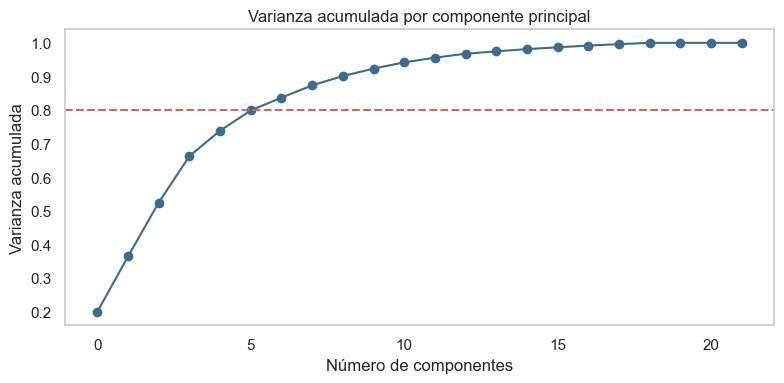

antes de PCA : (65818, 22)
después de PCA: (65818, 7)
varianza explicada por componente: [0.198 0.165 0.161 0.138 0.076 0.061 0.038]


In [105]:
# Hora: lo que importa es si el siniestro es nocturno (Notebook 2: la gravedad está por encima del promedio de 22 a 7 h)
datos["nocturno"] = ((datos["hora"] >= 22) | (datos["hora"] <= 7)).astype(int)
datos["fin_de_semana"] = (datos["dia_semana"] >= 5).astype(int)

# Categorías con menos del 2 % de los siniestros -> "OTRO"
categorias_mejora = datos[categoricas].copy()
for columna in categoricas:
    frecuencia = categorias_mejora[columna].value_counts(normalize=True) # frecuencia relativa de cada categoría
    raras = list(frecuencia[frecuencia < 0.02].index) # categorías con menos del 2 % de los siniestros
    categorias_mejora[columna] = categorias_mejora[columna].replace(raras, "OTRO")

# Numéricas escaladas + indicadoras sin escalar (quedan en 0 y 1)
numericas_mejora = ["nocturno", "fin_de_semana", "cantidad_victimas", "edad_media_victimas"]
X_mejora = pd.concat([pd.DataFrame(StandardScaler().fit_transform(datos[numericas_mejora]), columns=numericas_mejora),
                      pd.get_dummies(categorias_mejora, dtype=float)], axis=1) # concatenar columnas de indicadoras

# PCA: cuántos componentes hacen falta para retener el 80 % de la varianza (Notebook 27)
varianza_acumulada = PCA().fit(X_mejora).explained_variance_ratio_.cumsum() # varianza acumulada por componente
plt.plot(varianza_acumulada, marker="o", color="#3E6B89")
plt.axhline(0.80, color="#C46A5E", linestyle="--") # línea de referencia para el 80 % de varianza
plt.title("Varianza acumulada por componente principal")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.grid()
plt.tight_layout()
plt.show()

r = int((varianza_acumulada >= 0.80).argmax()) + 1 # número mínimo de componentes para retener al menos el 80 % de la varianza, el +1 es porque el índice empieza en 0
pca = PCA(n_components=r, random_state=42).fit(X_mejora)
X_pca = pca.transform(X_mejora)

print("antes de PCA :", X_mejora.shape)
print("después de PCA:", X_pca.shape)
print("varianza explicada por componente:", pca.explained_variance_ratio_.round(3))

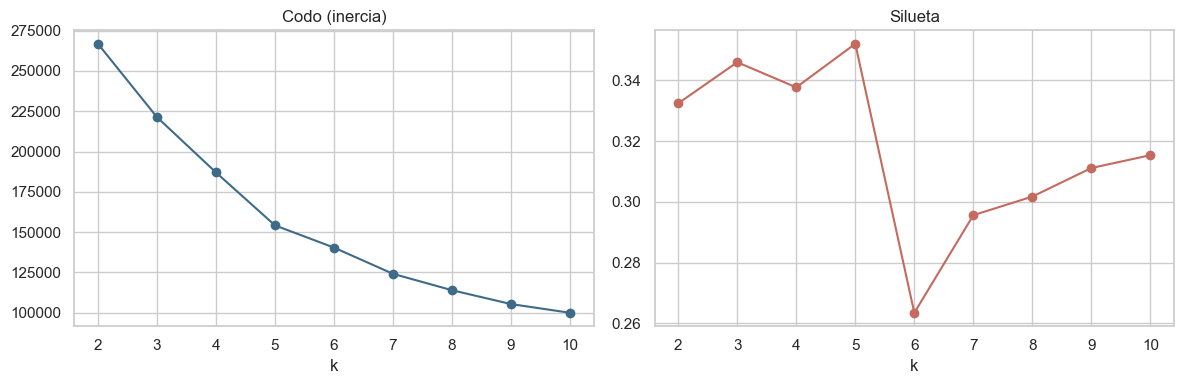

,inercia,silueta,estabilidad_ARI,grupo_mas_chico_%
k,,,,
2,266870.760,0.332,1.000,19.092
3,221364.042,0.346,0.931,12.728
4,187048.120,0.338,0.989,12.913
5,154194.766,0.352,0.995,2.235
6,140394.656,0.264,0.613,2.235
7,124119.864,0.296,1.000,2.235
8,113949.387,0.302,1.000,0.851
9,105352.755,0.311,0.998,0.851
10,99942.634,0.315,0.999,0.851


In [106]:
resultados_mejora = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    otra_semilla = KMeans(n_clusters=k, n_init=10, random_state=7).fit(X_pca)
    resultados_mejora.append({
        "k": k,
        "inercia": kmeans.inertia_,
        "silueta": silhouette_score(X_pca, kmeans.labels_, sample_size=10000, random_state=42),
        "estabilidad_ARI": adjusted_rand_score(kmeans.labels_, otra_semilla.labels_),
        "grupo_mas_chico_%": pd.Series(kmeans.labels_).value_counts(normalize=True).min() * 100})
resultados_mejora = pd.DataFrame(resultados_mejora).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
resultados_mejora["inercia"].plot(marker="o", ax=axes[0], color="#3E6B89", title="Codo (inercia)")
resultados_mejora["silueta"].plot(marker="o", ax=axes[1], color="#C46A5E", title="Silueta")
plt.tight_layout()
plt.show()
resultados_mejora.round(3)

In [107]:
# Aplicación del criterio
candidatos = resultados_mejora[(resultados_mejora["estabilidad_ARI"] >= 0.95) &
                               (resultados_mejora["grupo_mas_chico_%"] >= 2)] # seleccionar candidatos que cumplan con los criterios de estabilidad y tamaño mínimo
print("k que cumplen estabilidad y tamaño mínimo:", list(candidatos.index))
k_elegido = candidatos["silueta"].idxmax() # seleccionar el k con la mayor silueta entre los candidatos
print("k elegido (mayor silueta):", k_elegido)

k que cumplen estabilidad y tamaño mínimo: [2, 4, 5, 7]
k elegido (mayor silueta): 5


## 3.3 Comparación: modelo base vs. modelo mejorado

In [108]:
kmeans_final = KMeans(n_clusters=k_elegido, n_init=10, random_state=42).fit(X_pca)
datos["cluster"] = kmeans_final.labels_

base_k = KMeans(n_clusters=k_elegido, n_init=10, random_state=42).fit(X_base)
base_otra = KMeans(n_clusters=k_elegido, n_init=10, random_state=7).fit(X_base)

comparacion = pd.DataFrame({
    "silueta": [silhouette_score(X_base, base_k.labels_, sample_size=10000, random_state=42),
                silhouette_score(X_pca, kmeans_final.labels_, sample_size=10000, random_state=42)],
    "estabilidad_ARI": [adjusted_rand_score(base_k.labels_, base_otra.labels_),
                        resultados_mejora.loc[k_elegido, "estabilidad_ARI"]],
    "dimensiones": [X_base.shape[1], X_pca.shape[1]]},
    index=["base", "mejorado"])
comparacion.round(3)

,silueta,estabilidad_ARI,dimensiones
base,0.162,0.196,32
mejorado,0.352,0.995,7


**Lectura.** Con el mismo k = 5, el modelo mejorado sube la silueta de 0,16 a 0,35 y pasa de 32 a 7 dimensiones. La mejora más importante es la **estabilidad**: el modelo base cambia mucho con otra semilla (ARI 0,20), es decir, sus grupos dependen del azar; el mejorado da prácticamente los mismos grupos (ARI 0,995).

Sobre la elección de k: a diferencia del modelo base, ahora la silueta tiene su **máximo en k = 5**, y la inercia deja de bajar fuerte a partir de ahí. Cumplen el criterio de estabilidad y tamaño k = 2, 4, 5 y 7 (k = 3 y k = 6 cambian con la semilla), y el de mayor silueta es **k = 5**.

**¿Por qué mejoró la silueta?** Casi toda la mejora viene de reemplazar la hora por `nocturno`.

* **La parte real:** como muestra el gráfico de la sección 1.3, la gravedad no sube de a poco con la hora sino que cambia de nivel: hay un bloque de horas nocturnas (22 a 7 h) y otro diurno. `nocturno` representa justamente esa diferencia, y por eso los grupos se pueden nombrar y difieren en gravedad (Parte 4).
* **La parte mecánica:** una variable que sólo vale 0 o 1 deja a todos los siniestros nocturnos en un mismo punto y a los diurnos en otro, con un hueco en el medio. Eso arma grupos compactos y separados, que es lo que premia la silueta. Por eso el 0,35 contra 0,16 no alcanza como prueba por sí solo: hay que mirar también la estabilidad y la interpretación.
* **Lo que se pierde:** dentro de la noche y dentro del día ya no hay matices. Las 22 h valen lo mismo que las 3 h, y las 8 h lo mismo que las 17 h.

## 3.4 Perfil de Silhouette por punto

El promedio de la silueta puede esconder un grupo mal armado. Se grafica s(i) de cada siniestro, ordenado dentro de su grupo (como en la Notebook 26). Se usa una muestra de 10.000 siniestros porque el cálculo compara todos los puntos contra todos.

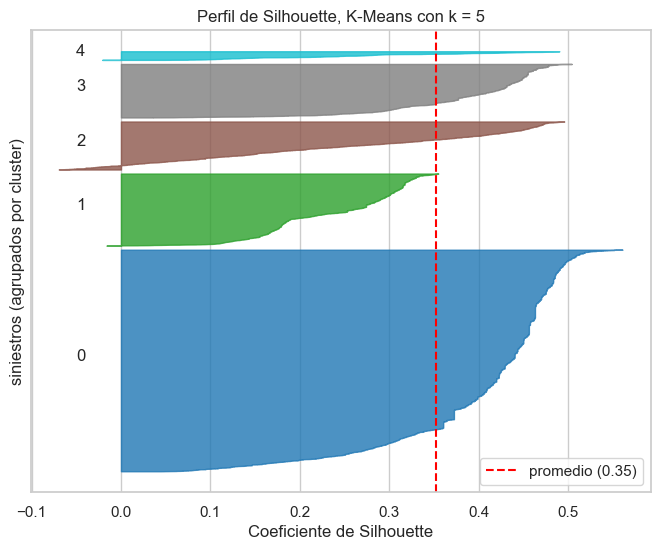

,silhouette,negativo_%
cluster,,
0,0.41,0.00
1,0.24,0.34
2,0.25,8.92
3,0.39,0.00
4,0.27,0.47


In [109]:
muestra_s = np.random.RandomState(42).choice(len(X_pca), 10000, replace=False)
etiquetas = kmeans_final.labels_[muestra_s]
valores_s = silhouette_samples(X_pca[muestra_s], etiquetas)

fig, ax = plt.subplots(figsize=(8, 6))
inicio = 0
colores = plt.cm.tab10(np.linspace(0, 1, k_elegido))
for cluster in range(k_elegido):
    s_cluster = np.sort(valores_s[etiquetas == cluster])
    fin = inicio + len(s_cluster)
    ax.fill_betweenx(np.arange(inicio, fin), 0, s_cluster, color=colores[cluster], alpha=0.8)
    ax.text(-0.05, (inicio + fin) / 2, str(cluster))
    inicio = fin + 100
ax.axvline(valores_s.mean(), color="red", linestyle="--", label=f"promedio ({valores_s.mean():.2f})")
ax.set_xlabel("Coeficiente de Silhouette")
ax.set_ylabel("siniestros (agrupados por cluster)")
ax.set_yticks([])
ax.set_title(f"Perfil de Silhouette, K-Means con k = {k_elegido}")
ax.legend()
plt.show()

perfil_silueta = pd.DataFrame({"cluster": etiquetas, "silhouette": valores_s, "negativo_%": (valores_s < 0) * 100})
perfil_silueta.groupby("cluster").mean().round(2)

**Lectura.** El perfil es bueno: los grupos de día hábil y de fin de semana de día no tienen valores negativos y su silueta promedio ronda 0,4. Los otros tres merecen comentario:

- **Personas mayores:** el 9 % de sus siniestros tiene silueta negativa, es decir, estarían mejor en otro grupo. Son casos en el borde (por ejemplo, edades intermedias) que K-Means asigna por cercanía. El núcleo del grupo está bien definido.
- **Nocturno:** casi no tiene negativos, pero su silueta promedio es más baja (0,24), porque junta noches de días hábiles y de fin de semana.
- **Varias víctimas:** silueta de 0,27, porque la cantidad de víctimas va de 2 a 26 y los casos con 2 víctimas quedan cerca de los demás grupos.

Ningún grupo está mal armado: los negativos se concentran en el borde del grupo que se define por la edad, que es una variable continua.

## 3.5 Comparación con otro algoritmo: DBSCAN

DBSCAN no necesita k: arma grupos por **densidad** y deja como ruido (etiqueta −1) los puntos aislados. Se prueba sobre el mismo espacio (PCA) con varios valores de `eps` (radio del vecindario) y `min_samples=20`. Como en la Notebook 26, la silueta de DBSCAN se calcula **sin el ruido**, porque el ruido no es un grupo.

In [ ]:
resultados_dbscan = []
for eps in [0.3, 0.5, 0.8, 1.0]:
    etiquetas_db = DBSCAN(eps=eps, min_samples=20).fit_predict(X_pca)
    sin_ruido = etiquetas_db != -1
    tamanios = pd.Series(etiquetas_db[sin_ruido]).value_counts(normalize=True)
    resultados_dbscan.append({
        "eps": eps,
        "clusters": tamanios.size,
        "ruido_%": (~sin_ruido).mean() * 100,
        "cluster_mas_grande_%": tamanios.max() * 100,
        "segundo_cluster_mas_grande_%": tamanios.nlargest(2).iloc[-1] * 100,
        "silueta_sin_ruido": silhouette_score(X_pca[sin_ruido], etiquetas_db[sin_ruido],
                                              sample_size=10000, random_state=42)})
resultados_dbscan = pd.DataFrame(resultados_dbscan).set_index("eps")
resultados_dbscan.round(3)

,clusters,ruido_%,cluster_mas_grande_%,segundo_cluster_mas_grande,silueta_sin_ruido
eps,,,,,
0.3,123,8.982,8.587,6.884,0.170
0.5,57,3.943,24.350,17.900,0.126
0.8,17,1.270,61.286,12.704,0.308
1.0,16,0.627,60.891,12.632,0.309


**Lectura.** DBSCAN no encuentra una agrupación útil en ningún caso:

- Con `eps` chico (0,3 y 0,5) arma **entre 57 y 123 grupos** diminutos: demasiados para describirlos.
- Con `eps` mayor (0,8 o 1,0) casi no deja ruido, pero mete el **61 % de los siniestros en un solo grupo** y reparte el resto en 15 o 16 grupos.
- La silueta sin ruido nunca supera 0,31, por debajo del 0,35 de K-Means, aun dejando afuera los puntos difíciles.

El motivo es que los siniestros no forman zonas densas separadas por huecos: son un continuo, y DBSCAN, que busca densidad, no tiene dónde cortar. K-Means, en cambio, parte el espacio en regiones compactas aunque no haya huecos, y eso da perfiles interpretables. **Se mantiene K-Means como algoritmo elegido** porque el siluete de K-Means es 0.35 y el de DBSCAN es de 0.30, ahora con una comparación medida y no sólo por elección previa.

---
# Parte 4 — Interpretación de los grupos

## 4.1 Perfil de cada grupo con K-Means

In [ ]:
datos["victima_peaton"] = (datos["modo_desplazamiento_victima"] == "PEATON").astype(int)
datos["victima_moto"] = (datos["modo_desplazamiento_victima"] == "MOTO").astype(int)
datos["victima_auto"] = (datos["modo_desplazamiento_victima"] == "AUTO").astype(int)
datos["autopista"] = (datos["tipo_de_via_siniestro"] == "AUTOPISTA").astype(int)
datos["contra_colectivo"] = (datos["contraparte_siniestro"] == "COLECTIVO").astype(int)

# Perfil de cada cluster. Se utliza datos[cluster] porque se quiere tomar lo obtenido en el clustering final de K-Means con PCA y k = 5.
perfil = datos.groupby("cluster").agg(
    siniestros=("id_siniestro", "size"),
    hora_mediana=("hora", "median"),
    nocturno=("nocturno", "mean"),
    fin_de_semana=("fin_de_semana", "mean"),
    cantidad_victimas=("cantidad_victimas", "mean"),
    edad_media=("edad_media_victimas", "mean"),
    victima_peaton=("victima_peaton", "mean"),
    victima_moto=("victima_moto", "mean"),
    victima_auto=("victima_auto", "mean"),
    autopista=("autopista", "mean"),
    contra_colectivo=("contra_colectivo", "mean"))
perfil.round(2)

,siniestros,hora_mediana,nocturno,fin_de_semana,cantidad_victimas,edad_media,victima_peaton,victima_moto,victima_auto,autopista,contra_colectivo
cluster,,,,,,,,,,,
0,35591,15.0,0.00,0.00,1.07,32.88,0.12,0.42,0.10,0.06,0.09
1,11956,6.0,1.00,0.33,1.10,34.28,0.11,0.41,0.17,0.07,0.07
2,8169,14.0,0.03,0.07,1.07,62.41,0.33,0.17,0.13,0.04,0.16
3,8631,15.0,0.00,1.00,1.10,34.89,0.12,0.38,0.15,0.07,0.07
4,1471,14.0,0.25,0.29,3.77,37.12,0.05,0.09,0.41,0.11,0.16


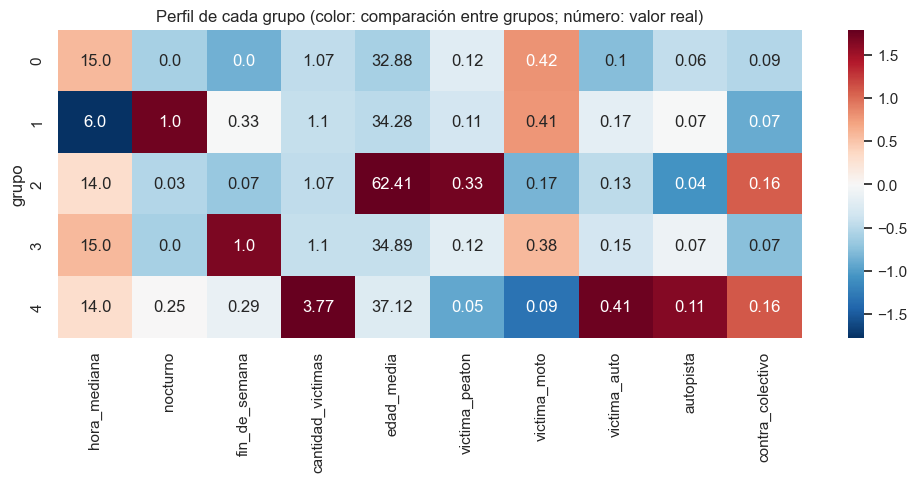

In [112]:
# Mapa de calor: cada columna estandarizada entre grupos (rojo = el grupo está por encima del resto)
perfil_relativo = (perfil - perfil.mean()) / perfil.std()

plt.figure(figsize=(12, 4))
sns.heatmap(perfil_relativo.drop(columns="siniestros"), annot=perfil.drop(columns="siniestros").round(2),
            fmt="", cmap="RdBu_r", center=0)
plt.title("Perfil de cada grupo (color: comparación entre grupos; número: valor real)")
plt.ylabel("grupo")
plt.show()

**Lectura.** Los cinco grupos combinan momento y tipo de víctima, y se pueden nombrar (los números de grupo pueden cambiar entre versiones de scikit-learn; en ese caso guiarse por el perfil):

| Grupo | Nombre | Rasgos | % de siniestros |
|---|---|---|---|
| 0 | **Día hábil, de día** | ni nocturno ni fin de semana; el grupo más grande | 54,1 % |
| 1 | **Nocturno** | todos entre las 22 y las 7 h; un tercio de fin de semana | 18,2 % |
| 2 | **Personas mayores** | edad media de 62 años; 33 % peatones, casi el triple que el resto; más choques con colectivo | 12,4 % |
| 3 | **Fin de semana, de día** | sábado o domingo, de día | 13,1 % |
| 4 | **Varias víctimas** | 3,8 víctimas en promedio; víctimas en auto; más autopista y colectivo | 2,2 % |

El momento del día y de la semana es lo que más separa a los grupos (0, 1 y 3). Los grupos 2 y 4 se separan por quiénes son las víctimas.

## 4.2 Validación externa: ¿algún grupo es más grave?

La gravedad no se usó para agrupar. Si los grupos difieren en gravedad, el clustering encontró perfiles con sentido para la prevención.

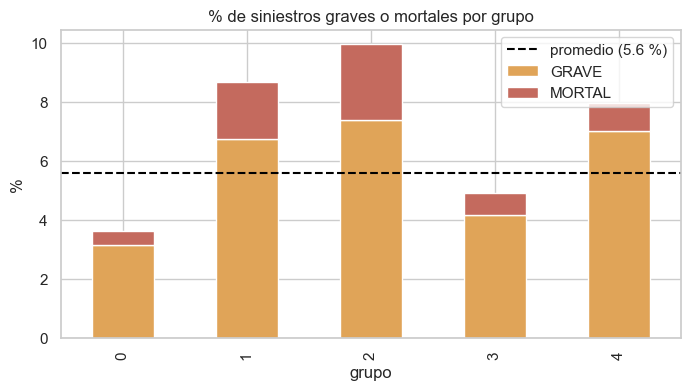

gravedad,GRAVE,MORTAL
cluster,,
0,3.13,0.47
1,6.73,1.95
2,7.38,2.57
3,4.17,0.73
4,7.00,0.95


In [113]:
gravedad_cluster = pd.crosstab(datos["cluster"], datos["gravedad"], normalize="index")[["GRAVE", "MORTAL"]] * 100
promedio = (datos["gravedad"].isin(["GRAVE", "MORTAL"])).mean() * 100

gravedad_cluster.plot(kind="bar", stacked=True, color=["#E0A458", "#C46A5E"])
plt.axhline(promedio, color="black", linestyle="--", label=f"promedio ({promedio:.1f} %)")
plt.title("% de siniestros graves o mortales por grupo")
plt.ylabel("%")
plt.xlabel("grupo")
plt.legend()
plt.show()
gravedad_cluster.round(2)

**Lectura.** Aunque la gravedad no se usó para agrupar, los grupos difieren mucho (promedio general: 5,6 % graves o mortales):

- **Personas mayores (grupo 2)** es el más grave: 10 % graves o mortales y **2,6 % mortales, dos veces y media el promedio** (1,0 %).
- **Nocturno (1)** y **varias víctimas (4)** están por encima del promedio (8,7 % y 8,0 %). El nocturno casi duplica la proporción de mortales (1,9 %), en línea con el EDA del Notebook 2.
- **Día hábil, de día (0)**, el grupo más grande, es el más leve: 3,6 % graves o mortales y 0,5 % mortales.

Esto le da uso práctico al clustering: el grupo de personas mayores es un perfil concreto (peatón mayor, de día, muchas veces con colectivo) para orientar campañas y cruces seguros, y el nocturno, para controles.

## 4.3 Los grupos en el espacio de las dos primeras componentes y en el mapa

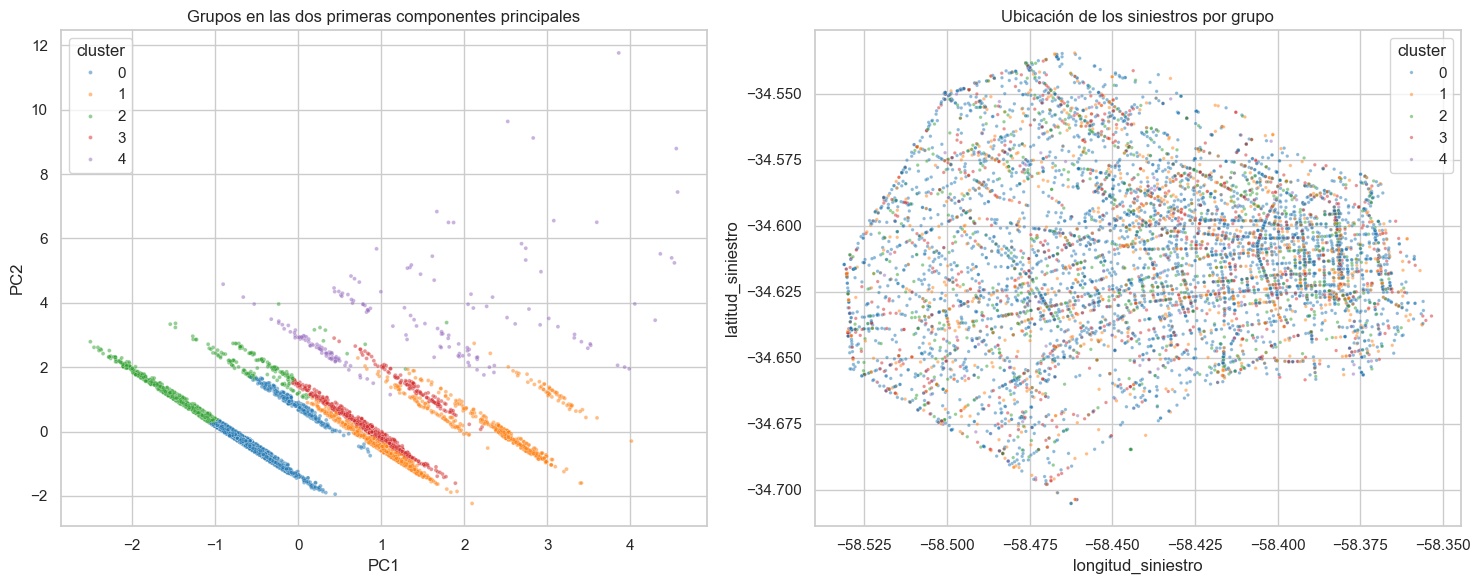

In [114]:
muestra = datos.sample(8000, random_state=42)
pca_muestra = X_pca[muestra.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=pca_muestra[:, 0], y=pca_muestra[:, 1], hue=muestra["cluster"],
                palette="tab10", s=8, alpha=0.5, ax=axes[0])
axes[0].set_title("Grupos en las dos primeras componentes principales")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sns.scatterplot(data=muestra, x="longitud_siniestro", y="latitud_siniestro", hue="cluster",
                palette="tab10", s=6, alpha=0.5, ax=axes[1])
axes[1].set_title("Ubicación de los siniestros por grupo")
plt.tight_layout()
plt.show()

**Lectura.** En las dos primeras componentes los grupos se ven separados en franjas, salvo el de varias víctimas (violeta), que aparece disperso arriba porque lo define una variable con valores extremos. En el mapa **los grupos están mezclados en toda la ciudad**: la ubicación no se usó para agrupar y los perfiles aparecen sobre las mismas avenidas, no en zonas propias.

---
# Conclusiones

1. **Algoritmo:** K-Means, por ser escalable e interpretable mediante centroides. Se comparó con DBSCAN: fragmenta los datos en decenas de grupos o junta el 61 % en uno solo, con menor silueta (≤ 0,31).
2. **Modelo base:** con todas las indicadoras estandarizadas, los grupos se armaban por una sola categoría, la silueta subía con k sin un máximo claro y el resultado cambiaba con la semilla (ARI 0,20).
3. **Mejora:** `nocturno` (22 a 7 h, las horas con gravedad por encima del promedio) y `fin_de_semana` en lugar de la hora y el día, indicadoras sin estandarizar, categorías raras agrupadas en `OTRO` y PCA al 80 % de la varianza. Con un criterio fijado de antemano (estabilidad, tamaño mínimo y mayor silueta) se eligió **k = 5**: silueta 0,35 y grupos prácticamente idénticos con otra semilla. La mayor parte de la mejora viene de `nocturno`.
4. **Validación:** codo, silueta promedio y por punto, estabilidad entre semillas, comparación con DBSCAN y gravedad real.
5. **Resultado:** cinco perfiles interpretables. El de **personas mayores** tiene dos veces y media la proporción de siniestros mortales y el **nocturno** casi el doble; el de **día hábil, de día** es el más leve.

**Limitaciones**

- La silueta es moderada (0,35), y en parte se debe a que `nocturno` y `fin_de_semana` valen 0 o 1. Los grupos sirven para describir perfiles, no son categorías "naturales".
- `nocturno` borra los matices dentro del día y de la noche (las 22 h valen lo mismo que las 3 h).
- La edad media falta en el 31 % de los siniestros y se imputó con la mediana; eso acerca esos casos a los grupos de edad típica.
- `SIN DATOS` se conserva como categoría y aparece en todos los grupos en proporciones parecidas, así que no distorsiona la agrupación.